In [1]:
import os
import tensorflow as tf

TRAIN_DIR = None
TEST_DIR = None

# Scan /kaggle/input for Training and Testing directories
for root, dirs, _ in os.walk('/kaggle/input'):
    for d in dirs:
        d_lower = d.lower()
        full_path = os.path.join(root, d)
        # Check that the directory contains class subfolders
        has_subdirs = any(os.path.isdir(os.path.join(full_path, s)) for s in os.listdir(full_path))
        if has_subdirs:
            if 'train' in d_lower and TRAIN_DIR is None:
                TRAIN_DIR = full_path
            elif ('test' in d_lower or 'val' in d_lower) and TEST_DIR is None:
                TEST_DIR = full_path

print(f"Training Directory: {TRAIN_DIR}")
print(f"Testing Directory:  {TEST_DIR}")

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    seed=123
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    seed=123
)

class_names = train_ds.class_names
print(f"\nLoaded {len(class_names)} classes: {class_names}")

Training Directory: /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Training
Testing Directory:  /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing
Found 5600 files belonging to 4 classes.


2026-09-24 05:19:02.794272: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Found 1600 files belonging to 4 classes.

Loaded 4 classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


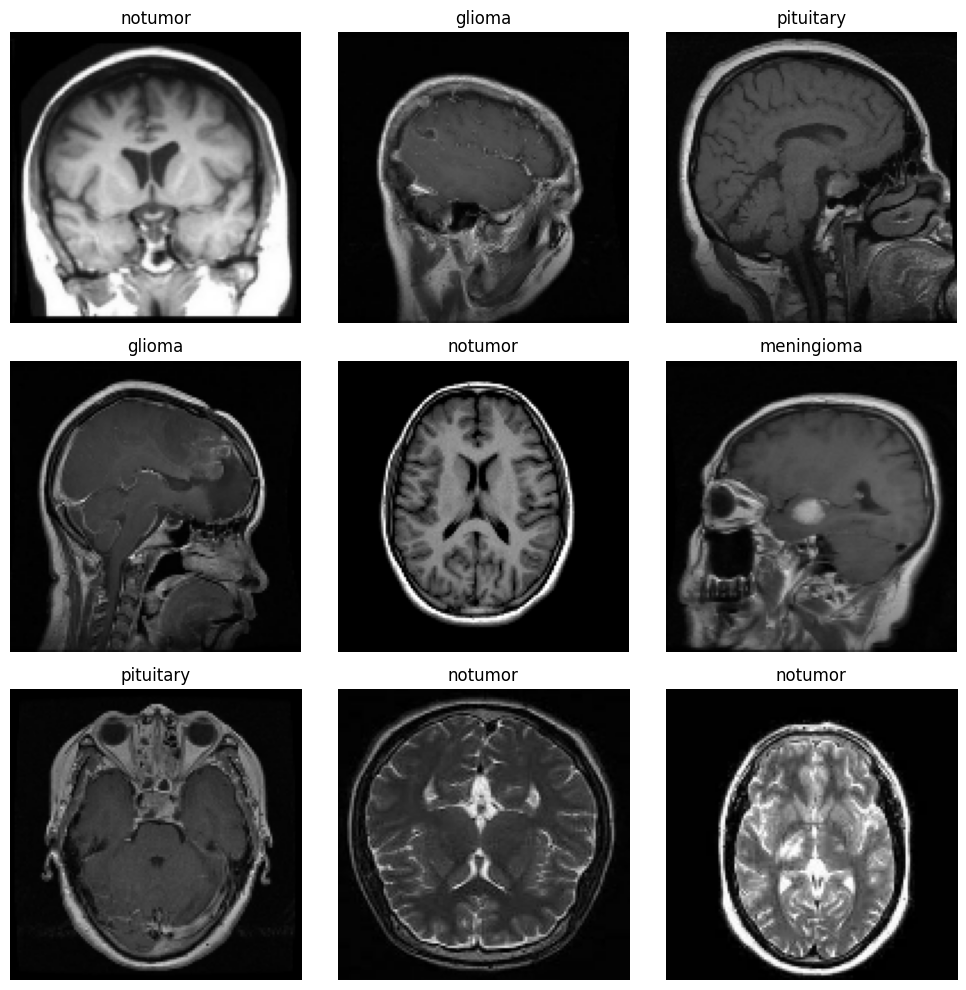

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.tight_layout()
plt.show()

In [3]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(128, 128, 3)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(len(class_names), activation='softmax')
])

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,156 (12.61 MB)

 Trainable params: 3,305,156 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# Custom callback to print cleanly rounded accuracy and loss every epoch
class RoundMetricsCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        train_acc = round(logs.get('accuracy', 0) * 100, 2)
        val_acc = round(logs.get('val_accuracy', 0) * 100, 2)
        train_loss = round(logs.get('loss', 0), 4)
        val_loss = round(logs.get('val_loss', 0), 4)
        print(f" -> Epoch {epoch + 1}: Train Acc = {train_acc}% | Val Acc = {val_acc}% | Train Loss = {train_loss} | Val Loss = {val_loss}")

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    verbose=2,
    callbacks=[RoundMetricsCallback()]
)

Epoch 1/10
 -> Epoch 1: Train Acc = 72.93% | Val Acc = 73.31% | Train Loss = 0.656 | Val Loss = 0.9214
175/175 - 104s - 596ms/step - accuracy: 0.7293 - loss: 0.6560 - val_accuracy: 0.7331 - val_loss: 0.9214
Epoch 2/10
 -> Epoch 2: Train Acc = 87.12% | Val Acc = 80.75% | Train Loss = 0.3327 | Val Loss = 0.7726
175/175 - 97s - 556ms/step - accuracy: 0.8712 - loss: 0.3327 - val_accuracy: 0.8075 - val_loss: 0.7726
Epoch 3/10
 -> Epoch 3: Train Acc = 92.45% | Val Acc = 81.31% | Train Loss = 0.1995 | Val Loss = 0.8621
175/175 - 96s - 547ms/step - accuracy: 0.9245 - loss: 0.1995 - val_accuracy: 0.8131 - val_loss: 0.8621
Epoch 4/10
 -> Epoch 4: Train Acc = 95.52% | Val Acc = 86.06% | Train Loss = 0.1201 | Val Loss = 0.8716
175/175 - 144s - 821ms/step - accuracy: 0.9552 - loss: 0.1201 - val_accuracy: 0.8606 - val_loss: 0.8716
Epoch 5/10
 -> Epoch 5: Train Acc = 97.41% | Val Acc = 89.06% | Train Loss = 0.078 | Val Loss = 0.9534
175/175 - 141s - 803ms/step - accuracy: 0.9741 - loss: 0.0780 - val_


--- Epoch Summary ---
Epoch 1: Train Accuracy = 72.93% | Val Accuracy = 73.31%
Epoch 2: Train Accuracy = 87.12% | Val Accuracy = 80.75%
Epoch 3: Train Accuracy = 92.45% | Val Accuracy = 81.31%
Epoch 4: Train Accuracy = 95.52% | Val Accuracy = 86.06%
Epoch 5: Train Accuracy = 97.41% | Val Accuracy = 89.06%
Epoch 6: Train Accuracy = 98.14% | Val Accuracy = 85.25%
Epoch 7: Train Accuracy = 98.37% | Val Accuracy = 89.19%
Epoch 8: Train Accuracy = 99.68% | Val Accuracy = 90.0%
Epoch 9: Train Accuracy = 99.3% | Val Accuracy = 88.06%
Epoch 10: Train Accuracy = 99.45% | Val Accuracy = 90.56%

Final Validation Accuracy: 90.56%
Final Validation Loss:     1.2207


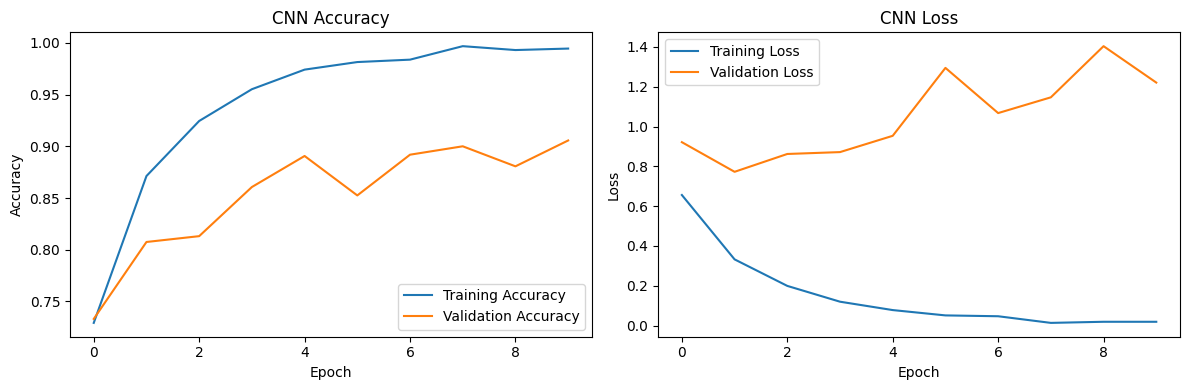

In [5]:
# Epoch-by-epoch rounded summary
print("\n--- Epoch Summary ---")
for i, (train_acc, val_acc) in enumerate(zip(history.history['accuracy'], history.history['val_accuracy']), start=1):
    print(f"Epoch {i}: Train Accuracy = {round(train_acc * 100, 2)}% | Val Accuracy = {round(val_acc * 100, 2)}%")

# Final evaluation
loss, accuracy = model.evaluate(val_ds, verbose=0)
print(f"\nFinal Validation Accuracy: {round(accuracy * 100, 2)}%")
print(f"Final Validation Loss:     {round(loss, 4)}")

# Plot metrics
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('CNN Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('CNN Loss')
plt.legend()

plt.tight_layout()
plt.show()